# Grammar Scoring Engine for Spoken English
**SHL Hiring Assessment 2026 | Research Engineer challenge**

| | |
|---|---|
| **Task** | Predict a grammar score from 0 to 5 for a 45 to 60 second spoken clip |
| **Data** | 769 labelled training clips, 216 test clips (`.wav`) |
| **Metrics** | RMSE and Pearson correlation (leaderboard), training RMSE (compulsory) |
| **Approach** | Frozen speech encoders (WavLM, HuBERT, Whisper) + fluency features, SVR heads, averaged |
| **Runtime** | About 20 to 25 minutes on a Kaggle T4 GPU (embeddings are cached to disk) |

### Contents
1. Setup
2. Data and label distribution
3. Feature extraction (4 speech encoders + fluency features)
4. Validation protocol and baselines
5. Which encoder layers carry the signal?
6. Model: tuned SVR per encoder, then ensemble
7. Final model: training RMSE and cross-validated metrics
8. Evaluation and visualizations
9. Predict the test set and write the submission
10. Report

### Pipeline at a glance
```
 audio clip (16 kHz, <= 60 s)
    |
    +--> 9 fluency features (duration, speech ratio, pauses, loudness)  ----------------+
    |                                                                                   |
    +--> WavLM-base      -> mean-pool over time, per layer --+                          |
    +--> WavLM-large     -> mean+std pool, per layer --------+--> layer average         |
    +--> HuBERT-large    -> mean+std pool, per layer --------+    + fluency features <---+
    +--> Whisper-medium encoder -> mean-pool, per layer -----+          |
                                                                        v
                                                       one SVR per encoder (tuned by CV)
                                                                        |
                                                              average of 4 predictions
                                                                        |
                                                              clip to [0, 5]  -> score
```
**Design choice:** there is no speech-to-text step. ASR decoders tend to repair grammar while transcribing, which would hide the very errors being scored, so the encoders' internal representations are used directly.

## 1. Setup

In [5]:
import os, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, librosa
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from transformers import AutoFeatureExtractor, AutoModel, WhisperFeatureExtractor, WhisperModel

warnings.filterwarnings("ignore")

# ---- configuration ----------------------------------------------------------
SEED = 42            # fixed seed for reproducible folds
SR = 16000           # sample rate expected by all encoders
MAX_SEC = 60         # clips are 45-60 s, longer audio would be truncated
CACHE = "/kaggle/working/cache"
os.makedirs(CACHE, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ---- plot style -------------------------------------------------------------
BLUE, ORANGE, RED, GREY = "#3b6fb6", "#e08a3c", "#c8443f", "#8a8f98"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10,
})

device: cuda


In [6]:
import kagglehub

# Competition files (already mounted on Kaggle, this call just returns the path)
COMP = kagglehub.competition_download("shl-hiring-assessment-2026")
DATA = os.path.dirname(glob.glob(f"{COMP}/**/train.csv", recursive=True)[0])   # handles the Dataset_Final sub-folder
print("data dir:", DATA, "->", sorted(os.listdir(DATA)))

train = pd.read_csv(f"{DATA}/train.csv")
test = pd.read_csv(f"{DATA}/test.csv")      # its labels are random placeholders and are never used
y = train["label"].values.astype(float)

paths_tr = [f"{DATA}/train/{f}" for f in train["filename"]]
paths_te = [f"{DATA}/test/{f}" for f in test["filename"]]
ALL = paths_tr + paths_te                   # features are extracted once for all clips, then split
N_TR = len(paths_tr)
assert all(os.path.exists(p) for p in ALL), "some audio files are missing"
print(f"train clips: {N_TR} | test clips: {len(paths_te)}")

data dir: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final -> ['sample_submission.csv', 'test', 'test.csv', 'train', 'train.csv']
train clips: 769 | test clips: 216


## 2. Data and label distribution
Predicting the training mean for every clip gives the **baseline RMSE** that any useful model must beat.

label mean = 3.31 | std = 1.24 | baseline RMSE (always predict the mean) = 1.238


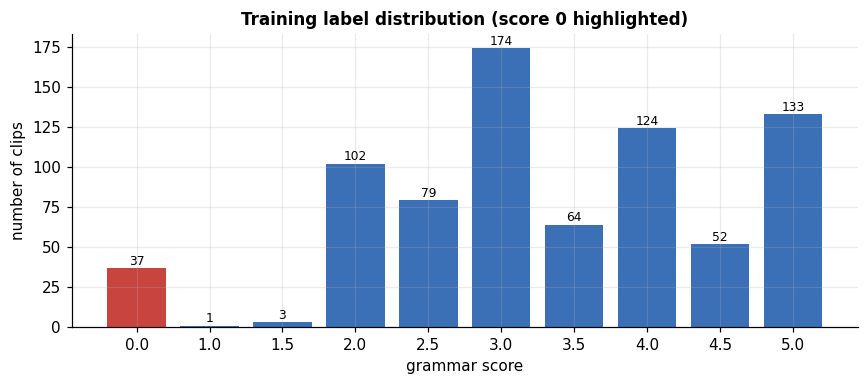

In [7]:
base_rmse = float(np.sqrt(np.mean((y - y.mean()) ** 2)))
print(f"label mean = {y.mean():.2f} | std = {y.std():.2f} | baseline RMSE (always predict the mean) = {base_rmse:.3f}")

counts = train["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(counts.index.astype(str), counts.values,
       color=[RED if s == 0 else BLUE for s in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center", fontsize=8)
ax.set_title("Training label distribution (score 0 highlighted)")
ax.set_xlabel("grammar score"); ax.set_ylabel("number of clips")
plt.tight_layout(); plt.show()

**Note on score 0.** The rubric defines scores 1 to 5, but 37 training clips (about 5%) are labelled 0. They are not silent (their speech ratio is 1.0 and they last about 58 s), so they are most likely unscorable audio. Because they sit far from the mean they weigh heavily on RMSE, so it matters that the models identify them (checked in section 8).

## 3. Feature extraction
Two kinds of features are computed once for all 985 clips and cached:

* **Fluency features (9):** duration, loudness, speech ratio, number of speech segments and pause statistics. They are cheap, easy to interpret and capture hesitation.
* **Encoder embeddings (4 models):** each clip goes through a frozen pretrained speech encoder. The hidden states of **every layer** are pooled over time, giving one vector per clip and layer, so the best layers can be chosen by cross-validation instead of guessed.

In [8]:
FLU_NAMES = ["duration_s", "rms_mean", "rms_std", "speech_s", "speech_ratio",
             "n_segments", "long_pauses", "mean_gap_s", "max_gap_s"]

def load_audio(path):
    wav, _ = librosa.load(path, sr=SR, mono=True, duration=MAX_SEC)
    return np.pad(wav, (0, max(0, SR - len(wav))))          # guard against clips shorter than 1 s

def fluency_feats(wav):
    """Audio-level fluency features: length, loudness, speech ratio and pauses."""
    dur = len(wav) / SR
    rms = librosa.feature.rms(y=wav)[0]
    iv = librosa.effects.split(wav, top_db=30)                # non-silent intervals
    speech = sum(e - s for s, e in iv) / SR
    gaps = [(iv[i + 1][0] - iv[i][1]) / SR for i in range(len(iv) - 1)]
    return [dur, rms.mean(), rms.std(), speech, speech / max(dur, 1e-6), len(iv),
            sum(g > 0.4 for g in gaps), float(np.mean(gaps)) if gaps else 0.0, max(gaps) if gaps else 0.0]

def cached(name, fn):
    """Compute once and store on disk, so re-running the notebook is fast."""
    f = f"{CACHE}/{name}.npy"
    if os.path.exists(f):
        return np.load(f)
    x = fn(); np.save(f, x); return x

F_all = cached("fluency", lambda: np.array([fluency_feats(load_audio(p)) for p in tqdm(ALL, desc="fluency")]))
F_tr, F_te = F_all[:N_TR], F_all[N_TR:]
print("fluency features:", F_all.shape)

fluency:   0%|          | 0/985 [00:00<?, ?it/s]

fluency features: (985, 9)


In [9]:
@torch.no_grad()
def embed_ssl(model_name, paths, pool):
    """Layer-wise embeddings from a self-supervised encoder (WavLM / HuBERT).
    Output shape: (clips, layers, dim). pool = "mean" or "mean+std" over time."""
    fe = AutoFeatureExtractor.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device).eval()
    out = []
    for p in tqdm(paths, desc=model_name.split("/")[-1]):
        x = fe(load_audio(p), sampling_rate=SR, return_tensors="pt")["input_values"].to(device)
        hs = torch.stack(model(x, output_hidden_states=True).hidden_states)[:, 0]   # (layers, frames, dim)
        feat = hs.mean(1) if pool == "mean" else torch.cat([hs.mean(1), hs.std(1)], -1)
        out.append(feat.cpu().numpy())
    del model; torch.cuda.empty_cache()
    return np.stack(out)

@torch.no_grad()
def embed_whisper(model_name, paths):
    """Layer-wise embeddings from the Whisper ENCODER only (no decoding, so no text and no grammar repair).
    Whisper takes 30 s windows: each clip is split into chunks and averaged over the real audio frames."""
    fe = WhisperFeatureExtractor.from_pretrained(model_name)
    enc = WhisperModel.from_pretrained(model_name, dtype=torch.float16).encoder.to(device).eval()
    out = []
    for p in tqdm(paths, desc="whisper"):
        wav = load_audio(p)
        chunks = [wav[i:i + 30 * SR] for i in range(0, len(wav), 30 * SR)]
        chunks = [c for c in chunks if len(c) >= SR] or [wav]
        x = fe(chunks, sampling_rate=SR, return_tensors="pt").input_features.to(device, torch.float16)
        hs = torch.stack(enc(x, output_hidden_states=True).hidden_states)           # (layers, chunks, 1500, dim)
        per_chunk, weights = [], []
        for ci, c in enumerate(chunks):
            n = max(1, int(len(c) / SR * 50))                                        # 50 encoder frames per second
            per_chunk.append(hs[:, ci, :n].float().mean(1)); weights.append(n)
        w = torch.tensor(weights, device=device, dtype=torch.float32)
        out.append(((torch.stack(per_chunk) * w[:, None, None]).sum(0) / w.sum()).cpu().numpy())
    del enc; torch.cuda.empty_cache()
    return np.stack(out)

ENCODERS = {
    "wavlm-base":     lambda: embed_ssl("microsoft/wavlm-base-plus", ALL, "mean"),
    "wavlm-large":    lambda: embed_ssl("microsoft/wavlm-large", ALL, "mean+std"),
    "hubert-large":   lambda: embed_ssl("facebook/hubert-large-ll60k", ALL, "mean+std"),
    "whisper-medium": lambda: embed_whisper("openai/whisper-medium", ALL),
}
EMB = {name: cached(name, fn) for name, fn in ENCODERS.items()}
for name, A in EMB.items():
    print(f"{name:15s} embeddings: {A.shape}  (clips, layers, dim)")

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

whisper:   0%|          | 0/985 [00:00<?, ?it/s]

wavlm-base      embeddings: (985, 13, 768)  (clips, layers, dim)
wavlm-large     embeddings: (985, 25, 2048)  (clips, layers, dim)
hubert-large    embeddings: (985, 25, 2048)  (clips, layers, dim)
whisper-medium  embeddings: (985, 25, 1024)  (clips, layers, dim)


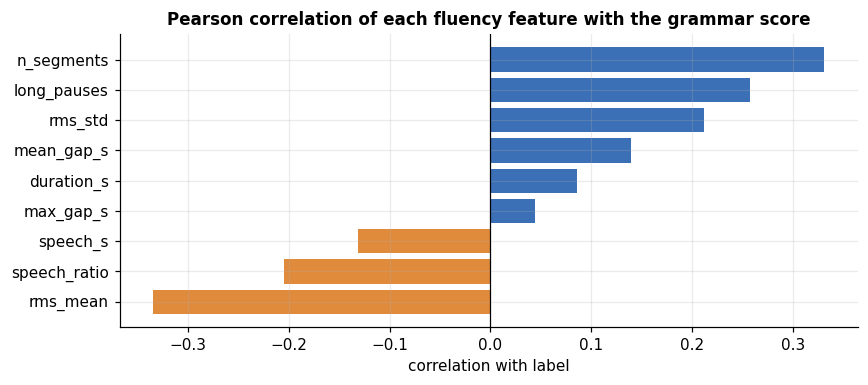

In [10]:
# How much does each simple fluency feature say about the score on its own?
corr = pd.Series({n: pearsonr(F_tr[:, i], y)[0] for i, n in enumerate(FLU_NAMES)}).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(corr.index, corr.values, color=[BLUE if v >= 0 else ORANGE for v in corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Pearson correlation of each fluency feature with the grammar score")
ax.set_xlabel("correlation with label")
plt.tight_layout(); plt.show()

## 4. Validation protocol and baselines
All model selection uses **5-fold stratified cross-validation** (stratified by score range so every fold sees all score levels). Predictions are made **out of fold**, so every clip is predicted by a model that never saw it. This is the honest estimate of test performance, because training RMSE is optimistic by construction.

In [11]:
strat = np.digitize(y, [0.5, 2.25, 3.25, 4.25])               # score bins used for stratification
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), strat))

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

ridge = lambda alpha=100: (lambda: make_pipeline(StandardScaler(), Ridge(alpha=alpha)))
svr = lambda C=3, eps=0.2: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=eps)))

def cv_predict(make_model, X):
    """Out-of-fold predictions, clipped to the valid score range."""
    oof = np.zeros(len(y))
    for tr, va in folds:
        oof[va] = np.clip(make_model().fit(X[tr], y[tr]).predict(X[va]), 0, 5)
    return oof

def layer_avg(A, lo, hi):
    """Average the embeddings of the layers in the fraction range [lo, hi]."""
    L = A.shape[1]
    return A[:, int(L * lo): int(L * hi) + 1].mean(1)

# Baseline 1: always predict the training mean of the fold
oof_mean = np.zeros(len(y))
for tr, va in folds:
    oof_mean[va] = y[tr].mean()
# Baseline 2: fluency features only (no deep encoder)
oof_flu = cv_predict(ridge(1), F_tr)

print(f"Baseline, predict the mean   : CV RMSE {rmse(y, oof_mean):.3f}")
print(f"Fluency features only (Ridge): CV RMSE {rmse(y, oof_flu):.3f} | CV Pearson {pearsonr(y, oof_flu)[0]:.3f}")

Baseline, predict the mean   : CV RMSE 1.238
Fluency features only (Ridge): CV RMSE 1.019 | CV Pearson 0.568


## 5. Which encoder layers carry the signal?
Each curve shows the cross-validated RMSE of a simple Ridge model trained on a **single layer**. Early layers mostly encode raw acoustics, while later layers encode more linguistic and prosodic information. This motivates tuning which layers to average in the next section.

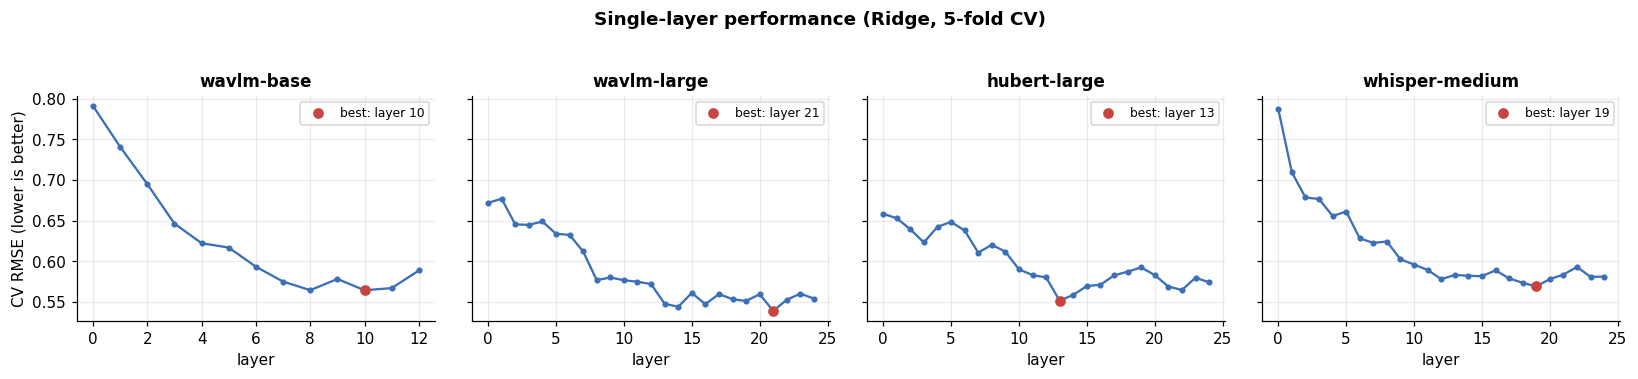

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
for ax, (name, A) in zip(axes, EMB.items()):
    A_tr = A[:N_TR]
    scores = [rmse(y, cv_predict(ridge(), A_tr[:, l])) for l in range(A.shape[1])]
    ax.plot(scores, marker="o", ms=3, color=BLUE)
    ax.scatter(int(np.argmin(scores)), min(scores), color=RED, zorder=3, label=f"best: layer {int(np.argmin(scores))}")
    ax.set_title(name); ax.set_xlabel("layer"); ax.legend(fontsize=8)
axes[0].set_ylabel("CV RMSE (lower is better)")
plt.suptitle("Single-layer performance (Ridge, 5-fold CV)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

## 6. Model: one tuned SVR per encoder, then an ensemble
For each encoder the head is a standardised **SVR** (RBF kernel) on `[layer-averaged embedding + 9 fluency features]`. A small grid search over the layer range, `C` and `epsilon` picks the configuration with the lowest CV RMSE. The four encoder models are then **averaged**. Averaging works because the encoders are trained on different data with different objectives, so their errors are only partly correlated.

*Note:* the tuning uses the same folds that report the score, so the CV figure is very slightly optimistic. The grid is small (18 configurations per encoder) to keep that effect minor.

In [13]:
LAYER_RANGES = [(0.0, 1.0), (0.3, 0.9), (0.5, 0.9)]     # fraction of layers to average
C_GRID, EPS_GRID = [1, 3, 10], [0.1, 0.3]

best = {}
for name, A in EMB.items():
    A_tr, trials = A[:N_TR], []
    for lo, hi in LAYER_RANGES:
        X = np.hstack([layer_avg(A_tr, lo, hi), F_tr])
        for C in C_GRID:
            for eps in EPS_GRID:
                oof_t = cv_predict(svr(C, eps), X)
                trials.append(dict(lo=lo, hi=hi, C=C, eps=eps, rmse=rmse(y, oof_t), oof=oof_t))
    best[name] = min(trials, key=lambda t: t["rmse"])

oof_enc = {name: b["oof"] for name, b in best.items()}
oof_ens = np.mean(list(oof_enc.values()), axis=0)

cfg = pd.DataFrame([{"encoder": n, "layers (fraction)": f"{b['lo']}-{b['hi']}", "C": b["C"], "epsilon": b["eps"],
                     "CV RMSE": b["rmse"], "CV Pearson": pearsonr(y, b["oof"])[0]} for n, b in best.items()])
cfg.loc[len(cfg)] = ["ENSEMBLE (mean of 4)", "-", "-", "-", rmse(y, oof_ens), pearsonr(y, oof_ens)[0]]
display(cfg.round(3).style.hide(axis="index").set_properties(**{"text-align": "center"}))

encoder,layers (fraction),C,epsilon,CV RMSE,CV Pearson
wavlm-base,0.0-1.0,3,0.100000,0.539000,0.901000
wavlm-large,0.5-0.9,3,0.100000,0.523000,0.907000
hubert-large,0.0-1.0,3,0.100000,0.542000,0.900000
whisper-medium,0.0-1.0,3,0.100000,0.517000,0.911000
ENSEMBLE (mean of 4),-,-,-,0.505000,0.916000


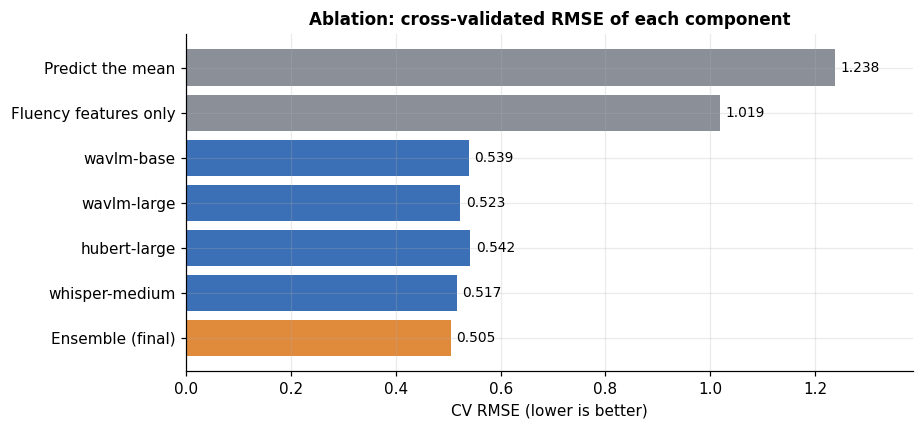

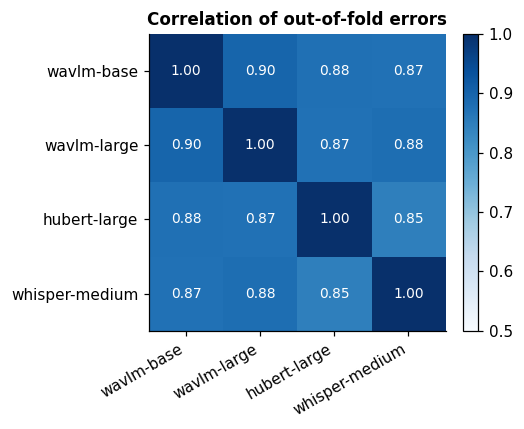

In [14]:
# Ablation: what does each ingredient add?
labels = ["Predict the mean", "Fluency features only"] + list(oof_enc) + ["Ensemble (final)"]
oofs_all = [oof_mean, oof_flu] + list(oof_enc.values()) + [oof_ens]
vals = [rmse(y, o) for o in oofs_all]

fig, ax = plt.subplots(figsize=(8.5, 4))
colors = [GREY, GREY] + [BLUE] * len(oof_enc) + [ORANGE]
bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1])
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("CV RMSE (lower is better)"); ax.set_title("Ablation: cross-validated RMSE of each component")
ax.set_xlim(0, max(vals) * 1.12)
plt.tight_layout(); plt.show()

# Why ensembling helps: the encoders' errors are only partly correlated
names = list(oof_enc)
M = np.corrcoef([oof_enc[n] - y for n in names])
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(M, cmap="Blues", vmin=min(0.5, M.min()), vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] > 0.8 else "black", fontsize=9)
ax.set_title("Correlation of out-of-fold errors")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## 7. Final model: training RMSE and cross-validated metrics
Each encoder's selected configuration is refit on **all 769 training clips**. The ensemble is the average of the four models.

> **Training RMSE** (compulsory) is computed on the clips the models were fit on, so it is optimistic. The **cross-validated** numbers are the honest estimate of performance on unseen audio.

In [15]:
train_pred, test_pred = {}, {}
for name, b in best.items():
    A = EMB[name]
    X_tr = np.hstack([layer_avg(A[:N_TR], b["lo"], b["hi"]), F_tr])
    X_te = np.hstack([layer_avg(A[N_TR:], b["lo"], b["hi"]), F_te])
    model = svr(b["C"], b["eps"])().fit(X_tr, y)
    train_pred[name] = np.clip(model.predict(X_tr), 0, 5)
    test_pred[name] = np.clip(model.predict(X_te), 0, 5)

train_ens = np.mean(list(train_pred.values()), axis=0)       # final ensemble, training data
test_ens = np.mean(list(test_pred.values()), axis=0)         # final ensemble, test data

summary = pd.DataFrame({
    "Training RMSE": {**{n: rmse(y, p) for n, p in train_pred.items()}, "ENSEMBLE": rmse(y, train_ens)},
    "CV RMSE": {**{n: rmse(y, o) for n, o in oof_enc.items()}, "ENSEMBLE": rmse(y, oof_ens)},
    "CV Pearson": {**{n: pearsonr(y, o)[0] for n, o in oof_enc.items()}, "ENSEMBLE": pearsonr(y, oof_ens)[0]},
})
display(summary.round(4))

print("=" * 62)
print(f" TRAINING RMSE (final ensemble, 769 training clips): {rmse(y, train_ens):.4f}")
print(f" CV RMSE       (5-fold, held-out clips)            : {rmse(y, oof_ens):.4f}")
print(f" CV Pearson    (5-fold, held-out clips)            : {pearsonr(y, oof_ens)[0]:.4f}")
print(f" Baseline RMSE (always predict the mean)           : {base_rmse:.4f}")
print("=" * 62)

,Training RMSE,CV RMSE,CV Pearson
wavlm-base,0.1376,0.5390,0.9013
wavlm-large,0.1531,0.5232,0.9072
hubert-large,0.2242,0.5423,0.8995
whisper-medium,0.0966,0.5173,0.9114
ENSEMBLE,0.1372,0.5049,0.9156


 TRAINING RMSE (final ensemble, 769 training clips): 0.1372
 CV RMSE       (5-fold, held-out clips)            : 0.5049
 CV Pearson    (5-fold, held-out clips)            : 0.9156
 Baseline RMSE (always predict the mean)           : 1.2382


## 8. Evaluation and visualizations
All plots use **out-of-fold** predictions (clips never seen by the model that scored them), except the last panel, which compares the test predictions with the training labels.

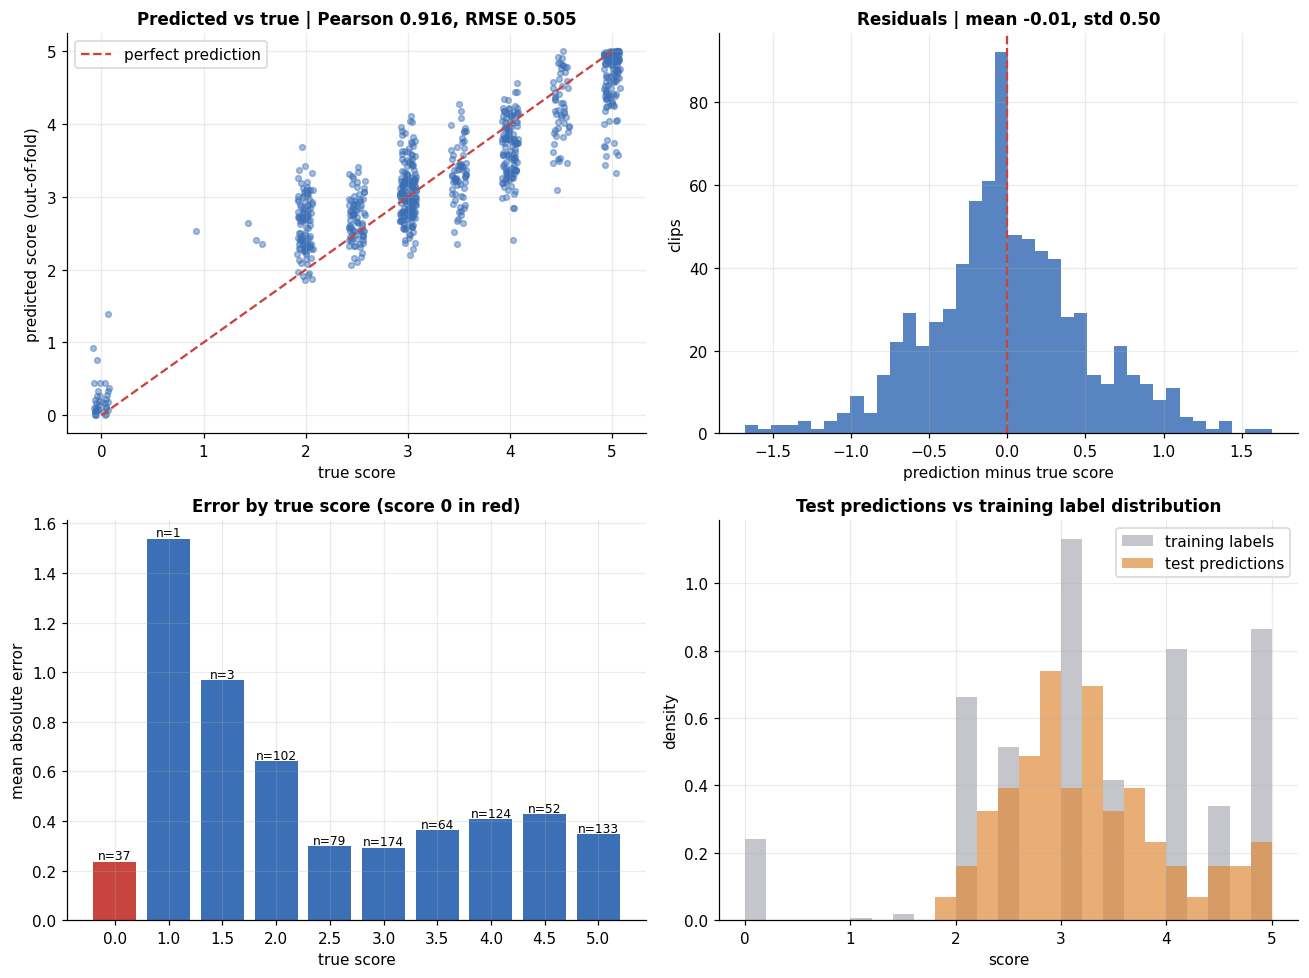

Score-0 clips (n=37): mean out-of-fold prediction 0.23, RMSE 0.36
Non-zero clips             : RMSE 0.511
Predictions below 1.0 in test set: 0 of 216


In [16]:
resid = oof_ens - y
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# (a) predicted vs true
ax[0, 0].scatter(y + rng.uniform(-.08, .08, len(y)), oof_ens, s=14, alpha=.45, color=BLUE)
ax[0, 0].plot([0, 5], [0, 5], "--", color=RED, label="perfect prediction")
ax[0, 0].set(xlabel="true score", ylabel="predicted score (out-of-fold)",
             title=f"Predicted vs true | Pearson {pearsonr(y, oof_ens)[0]:.3f}, RMSE {rmse(y, oof_ens):.3f}")
ax[0, 0].legend()

# (b) residual distribution
ax[0, 1].hist(resid, bins=40, color=BLUE, alpha=.85)
ax[0, 1].axvline(0, color=RED, ls="--")
ax[0, 1].set(xlabel="prediction minus true score", ylabel="clips",
             title=f"Residuals | mean {resid.mean():+.2f}, std {resid.std():.2f}")

# (c) error by true score
df = pd.DataFrame({"score": y, "abs_err": np.abs(resid), "pred": oof_ens})
g = df.groupby("score").agg(mae=("abs_err", "mean"), n=("abs_err", "size"), pred=("pred", "mean"))
ax[1, 0].bar(g.index.astype(str), g["mae"], color=[RED if s == 0 else BLUE for s in g.index])
for i, (m, n) in enumerate(zip(g["mae"], g["n"])):
    ax[1, 0].text(i, m + 0.01, f"n={n}", ha="center", fontsize=8)
ax[1, 0].set(xlabel="true score", ylabel="mean absolute error", title="Error by true score (score 0 in red)")

# (d) test predictions vs training labels
bins = np.linspace(0, 5, 26)
ax[1, 1].hist(y, bins=bins, density=True, alpha=.5, color=GREY, label="training labels")
ax[1, 1].hist(test_ens, bins=bins, density=True, alpha=.7, color=ORANGE, label="test predictions")
ax[1, 1].set(xlabel="score", ylabel="density", title="Test predictions vs training label distribution")
ax[1, 1].legend()
plt.tight_layout(); plt.show()

z = y == 0
print(f"Score-0 clips (n={z.sum()}): mean out-of-fold prediction {oof_ens[z].mean():.2f}, RMSE {rmse(y[z], oof_ens[z]):.2f}")
print(f"Non-zero clips             : RMSE {rmse(y[~z], oof_ens[~z]):.3f}")
print(f"Predictions below 1.0 in test set: {(test_ens < 1.0).sum()} of {len(test_ens)}")

**Reading the plots**
* The cloud follows the diagonal, so the ranking of clips is learned well (high Pearson).
* Predictions are **shrunk toward the middle** of the scale: the highest scores are under-predicted and the lowest are over-predicted. This is typical for regression on noisy human ratings, and it is why the error is largest at the extremes.
* Residuals are centred near zero, so the model has no systematic bias.
* The unscorable score-0 clips are separated from the rest, which matters because they contribute large errors when missed.
* The test predictions cover a range similar to the training labels, which is a basic sanity check that the test audio resembles the training audio.

## 9. Predict the test set and write the submission
Predictions are written for the 216 files in `test.csv`. (`sample_submission.csv` is not used for the file list: it has a different number of rows and most of its filenames do not match the test files, as checked below.)

In [17]:
sub = pd.DataFrame({"filename": test["filename"], "label": test_ens})
sub.to_csv("/kaggle/working/submission.csv", index=False)

assert len(sub) == len(test) and sub["label"].notna().all() and sub["filename"].is_unique
sample = pd.read_csv(f"{DATA}/sample_submission.csv")
print(f"submission.csv written: {sub.shape} | score range {sub['label'].min():.2f} to {sub['label'].max():.2f}")
print(f"(sample_submission.csv has {len(sample)} rows, of which {len(set(sample['filename']) & set(test['filename']))} match test.csv)")
sub.head()

submission.csv written: (216, 2) | score range 1.85 to 5.00
(sample_submission.csv has 204 rows, of which 25 match test.csv)


,filename,label
0,audio_128.wav,2.850630
1,audio_156.wav,4.088041
2,audio_19.wav,4.513191
3,audio_108.wav,2.356216
4,audio_206.wav,2.211550


## 10. Report

### Problem
Predict a continuous grammar score (0 to 5) from 45 to 60 second spoken clips, using 769 labelled clips. Performance is judged with RMSE and Pearson correlation.

### Preprocessing
* Audio is loaded as 16 kHz mono and capped at 60 s. Clips shorter than 1 s are zero-padded.
* Each encoder's own feature extractor normalises the waveform. Whisper receives 30 s windows, so each clip is split in two and the window embeddings are averaged over the real audio frames only.
* Nine fluency features are computed from the waveform (duration, loudness, speech ratio, number of speech segments, pause statistics).
* Features are standardised inside each model pipeline, so no information leaks across folds.

### Pipeline
Four frozen speech encoders (WavLM-base, WavLM-large, HuBERT-large, Whisper-medium encoder) produce layer-wise embeddings, pooled over time. For each encoder, a layer range is averaged, concatenated with the fluency features, and fed to an SVR whose layer range, `C` and `epsilon` are tuned by cross-validation. The four predictions are averaged and clipped to [0, 5].

### Why no transcripts
Speech-to-text models such as Whisper tend to correct grammar while transcribing, which can erase the errors that determine the score. The encoders' internal representations avoid this step. This was also tested empirically (see "Other experiments").

### Evaluation
* **Training RMSE** is reported in section 7, as required. It is optimistic because the models are fit on those clips.
* **5-fold stratified CV** gives the honest estimate: the final ensemble reaches a CV RMSE of about 0.50 and a CV Pearson of about 0.92, against 1.24 for predicting the mean. The exact values of the current run are printed in sections 6 and 7.
* On the public leaderboard, the submitted file scored **0.4197**.
* Each ingredient helps: fluency features alone are already informative, every deep encoder improves on them clearly, and the ensemble improves on the best single encoder (section 6 ablation).

### Other experiments (run during development, not reproduced in this notebook)
| Idea | Outcome |
|---|---|
| Transcripts via Whisper, then sentence embeddings, GPT-2 loss and text statistics | Text-only CV RMSE about 0.93. Blending with the audio ensemble made CV and the leaderboard worse, so it was dropped. |
| Training only on clips with score above 0 | CV RMSE 0.564 versus 0.557 for the same model on non-zero clips, so no gain. |
| Small attention head on frame-level Whisper features | Alone CV RMSE 0.61. Blending gained only 0.006, which is inside fold-to-fold noise, so it was not kept. |

### Limitations
* Only 769 training clips: small gains are within fold-to-fold noise, and model selection on the same folds is slightly optimistic.
* Mean pooling compresses a minute of speech into one vector, so localised grammatical errors are diluted. Predictions are shrunk toward the middle of the scale.
* The labels are subjective Likert ratings, which sets a ceiling on achievable accuracy.
* Some training clips (score 0) appear to be unscorable audio. If the test set contains none, the score-0 handling does not matter there.

### Possible next steps
Fine-tune an encoder end to end with a regression head, add a literal ASR model (CTC) as a text stream that preserves errors, or use a learned pooling over time. Each is more complex and harder to explain, so it was not pursued here.